CUSTOMER DATASET
   Customer_ID  Annual_Spending  Visits_Per_Month
0            1     19986.856612          2.018635
1            2     17446.942795          3.981823
2            3     20590.754152          2.489202
3            4     24092.119426          1.653831
4            5     17063.386501          3.158036
5            6     17063.452172          1.523325
6            7     24316.851262          2.667091
7            8     21069.738917          1.000000
8            9     16122.102456          1.437451
9           10     20170.240174          2.657489

Dataset Shape: (90, 3)

Dataset Information:
       Customer_ID  Annual_Spending  Visits_Per_Month
count    90.000000        90.000000         90.000000
mean     45.500000     52160.994261          6.748491
std      26.124701     30348.307324          3.815415
min       1.000000     10346.879021          1.000000
25%      23.250000     19623.808208          3.014699
50%      45.500000     50179.273602          6.466326
75%      

C:\Users\000ak\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


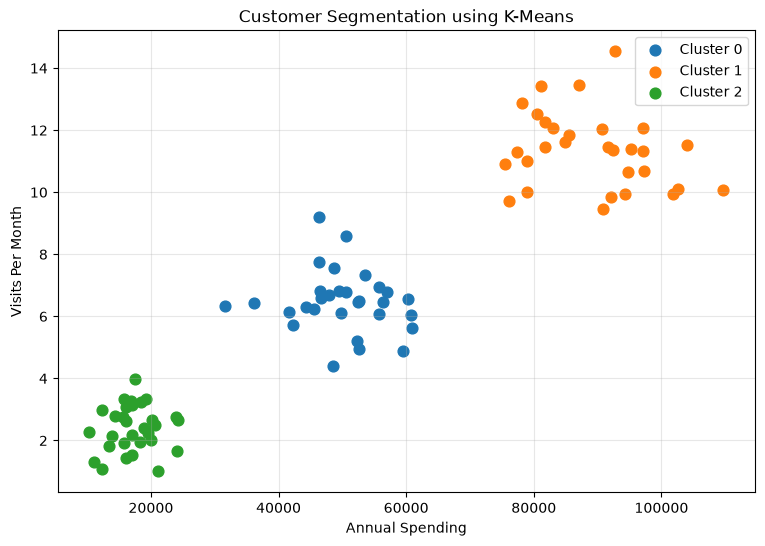


CLUSTER-WISE CUSTOMER ANALYSIS
         Annual_Spending  Visits_Per_Month  Number_of_Customers
Cluster                                                        
0               50090.19              6.48                   30
1               89145.38             11.36                   30
2               17247.41              2.41                   30


C:\Users\000ak\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\000ak\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\000ak\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


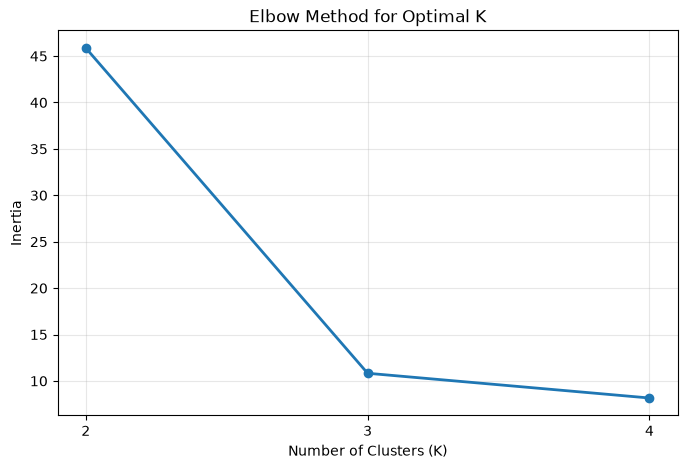

C:\Users\000ak\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\000ak\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\000ak\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(



SILHOUETTE SCORE COMPARISON
 K Value  Silhouette Score
       2            0.6521
       3            0.7363
       4            0.6404

Best K based on Silhouette Score: 3

DBSCAN CLUSTERING RESULTS
    Customer_ID  Annual_Spending  Visits_Per_Month  DBSCAN_Cluster
0             1     19986.856612          2.018635               0
1             2     17446.942795          3.981823               0
2             3     20590.754152          2.489202               0
3             4     24092.119426          1.653831               0
4             5     17063.386501          3.158036               0
5             6     17063.452172          1.523325               0
6             7     24316.851262          2.667091               0
7             8     21069.738917          1.000000               0
8             9     16122.102456          1.437451               0
9            10     20170.240174          2.657489               0
10           11     16146.329229          3.090773            

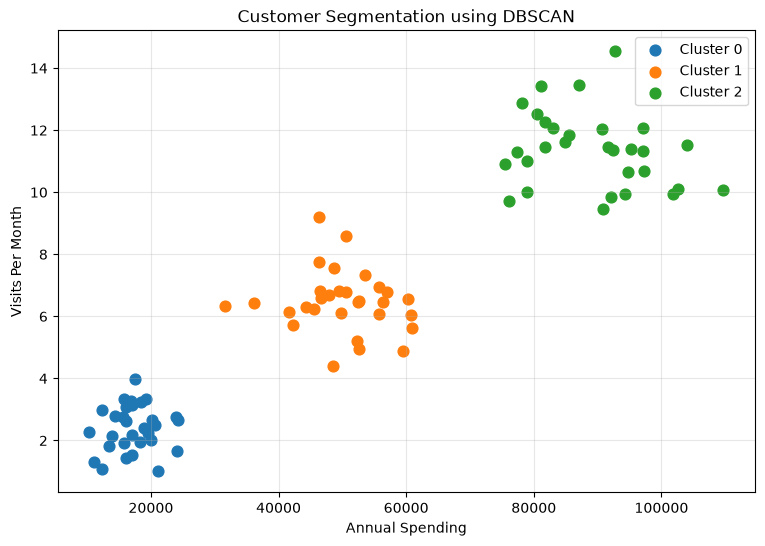


DBSCAN LABEL COUNT
DBSCAN_Cluster
0    30
1    30
2    30
Name: count, dtype: int64

Number of Noise Points: 0
-1 represents noise or outlier points.

CUSTOMER SEGMENT DESCRIPTIONS

Cluster 2: Low Spending Customers
Average Annual Spending: Rs. 17247.41
Average Monthly Visits: 2.41
Number of Customers: 30
Description: Customers who spend less and visit less frequently.

Cluster 0: Medium Spending Customers
Average Annual Spending: Rs. 50090.19
Average Monthly Visits: 6.48
Number of Customers: 30
Description: Customers who spend moderately and visit regularly.

Cluster 1: High Spending Customers
Average Annual Spending: Rs. 89145.38
Average Monthly Visits: 11.36
Number of Customers: 30
Description: Customers who spend more and visit frequently.

========== PRACTICAL 2 COMPLETED ==========
1. Customer dataset created successfully.
2. Feature scaling completed.
3. K-Means clustering performed with K=3.
4. Cluster visualization completed.
5. Average spending calculated.
6. Elbow method co

In [2]:

# PRACTICAL 2: CUSTOMER SEGMENTATION
# K-Means Clustering, Elbow Method, Silhouette Score and DBSCAN

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score

# STEP 1: CREATE CUSTOMER DATASET

np.random.seed(42)

low = pd.DataFrame({
    'Annual_Spending': np.random.normal(18000, 4000, 30),
    'Visits_Per_Month': np.random.normal(2.5, 0.8, 30)
})

medium = pd.DataFrame({
    'Annual_Spending': np.random.normal(50000, 7000, 30),
    'Visits_Per_Month': np.random.normal(6.5, 1.1, 30)
})

high = pd.DataFrame({
    'Annual_Spending': np.random.normal(90000, 9000, 30),
    'Visits_Per_Month': np.random.normal(11, 1.3, 30)
})

df = pd.concat([low, medium, high], ignore_index=True)

df['Annual_Spending'] = df['Annual_Spending'].clip(lower=5000)
df['Visits_Per_Month'] = df['Visits_Per_Month'].clip(lower=1, upper=15)
df['Customer_ID'] = range(1, len(df) + 1)

df = df[['Customer_ID', 'Annual_Spending', 'Visits_Per_Month']]

print("CUSTOMER DATASET")
print(df.head(10))
print("\nDataset Shape:", df.shape)
print("\nDataset Information:")
print(df.describe())

# STEP 2: FEATURE SCALING

features = ['Annual_Spending', 'Visits_Per_Month']

scaler = StandardScaler()
scaled_data = scaler.fit_transform(df[features])

print("\nFeature Scaling Completed Successfully")

# STEP 3: K-MEANS CLUSTERING (K=3)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

df['Cluster'] = kmeans.fit_predict(scaled_data)

print("\nK-MEANS CLUSTERING RESULTS")
print(df.head(10))

# STEP 4: VISUALIZE CUSTOMER CLUSTERS

plt.figure(figsize=(9, 6))

for cluster in sorted(df['Cluster'].unique()):
    group = df[df['Cluster'] == cluster]
    plt.scatter(
        group['Annual_Spending'],
        group['Visits_Per_Month'],
        label=f'Cluster {cluster}',
        s=60
    )

plt.title('Customer Segmentation using K-Means')
plt.xlabel('Annual Spending')
plt.ylabel('Visits Per Month')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# STEP 5: CLUSTER-WISE AVERAGE SPENDING

cluster_summary = df.groupby('Cluster').agg({
    'Annual_Spending': 'mean',
    'Visits_Per_Month': 'mean',
    'Customer_ID': 'count'
}).rename(columns={'Customer_ID': 'Number_of_Customers'})

print("\nCLUSTER-WISE CUSTOMER ANALYSIS")
print(cluster_summary.round(2))

# STEP 6: ELBOW METHOD (K=2, 3, 4)

inertia = []

for k in range(2, 5):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(scaled_data)
    inertia.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(2, 5), inertia, marker='o', linewidth=2)
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.xticks([2, 3, 4])
plt.grid(alpha=0.3)
plt.show()

# STEP 7: SILHOUETTE SCORE COMPARISON

silhouette_results = []

for k in range(2, 5):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(scaled_data)

    score = silhouette_score(scaled_data, labels)
    silhouette_results.append({
        'K Value': k,
        'Silhouette Score': round(score, 4)
    })

silhouette_df = pd.DataFrame(silhouette_results)

print("\nSILHOUETTE SCORE COMPARISON")
print(silhouette_df.to_string(index=False))

best_k = silhouette_df.loc[
    silhouette_df['Silhouette Score'].idxmax(), 'K Value'
]

print("\nBest K based on Silhouette Score:", best_k)

# STEP 8: DBSCAN CLUSTERING

dbscan = DBSCAN(eps=0.35, min_samples=4)

df['DBSCAN_Cluster'] = dbscan.fit_predict(scaled_data)

print("\nDBSCAN CLUSTERING RESULTS")
print(df[['Customer_ID', 'Annual_Spending',
          'Visits_Per_Month', 'DBSCAN_Cluster']].head(15))

# STEP 9: DBSCAN VISUALIZATION

plt.figure(figsize=(9, 6))

for cluster in sorted(df['DBSCAN_Cluster'].unique()):
    group = df[df['DBSCAN_Cluster'] == cluster]

    label = 'Noise (-1)' if cluster == -1 else f'Cluster {cluster}'

    plt.scatter(
        group['Annual_Spending'],
        group['Visits_Per_Month'],
        label=label,
        s=60
    )

plt.title('Customer Segmentation using DBSCAN')
plt.xlabel('Annual Spending')
plt.ylabel('Visits Per Month')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# STEP 10: DBSCAN LABEL ANALYSIS

print("\nDBSCAN LABEL COUNT")
print(df['DBSCAN_Cluster'].value_counts().sort_index())

noise_count = (df['DBSCAN_Cluster'] == -1).sum()

print("\nNumber of Noise Points:", noise_count)
print("-1 represents noise or outlier points.")

# STEP 11: THREE CUSTOMER SEGMENT DESCRIPTIONS

print("\nCUSTOMER SEGMENT DESCRIPTIONS")

for cluster in cluster_summary.sort_values(
    'Annual_Spending'
).index:

    spending = cluster_summary.loc[cluster, 'Annual_Spending']
    visits = cluster_summary.loc[cluster, 'Visits_Per_Month']
    count = cluster_summary.loc[cluster, 'Number_of_Customers']

    if spending < 30000:
        segment = "Low Spending Customers"
        description = "Customers who spend less and visit less frequently."

    elif spending < 70000:
        segment = "Medium Spending Customers"
        description = "Customers who spend moderately and visit regularly."

    else:
        segment = "High Spending Customers"
        description = "Customers who spend more and visit frequently."

    print(f"\nCluster {cluster}: {segment}")
    print("Average Annual Spending: Rs.", round(spending, 2))
    print("Average Monthly Visits:", round(visits, 2))
    print("Number of Customers:", int(count))
    print("Description:", description)

# FINAL SUMMARY

print("\n========== PRACTICAL 2 COMPLETED ==========")
print("1. Customer dataset created successfully.")
print("2. Feature scaling completed.")
print("3. K-Means clustering performed with K=3.")
print("4. Cluster visualization completed.")
print("5. Average spending calculated.")
print("6. Elbow method completed.")
print("7. Silhouette score comparison completed.")
print("8. DBSCAN clustering performed.")
print("9. Three customer segments identified.")
